 📊 TABLA A: GANANCIA MÁXIMA POR SEMILLA


,Semilla,Exp_A_5HP,Exp_B_11HP,Exp_C_16HP,Exp_C_14HP_Alt
0,179213,95.51,92.30,92.43,92.19
1,200017,92.23,89.58,89.71,92.53
2,323503,92.20,96.55,90.66,88.49
3,543121,95.65,93.08,89.45,89.85
4,607681,94.97,93.03,88.77,91.33
5,611147,93.36,92.41,91.06,90.30
6,618271,90.02,89.47,95.17,93.85
7,726769,90.62,91.56,92.85,93.25
8,897563,94.00,91.00,91.39,91.55
9,898117,92.29,90.96,92.97,94.01



 🔬 TABLA B: RESULTADOS WILCOXON (MUESTRA TOTAL)


,Comparación,Hipótesis,N,p-valor,Dif (<0.05),Ganador
0,Exp_A_5HP vs Exp_B_11HP,¿Aumentar de 5 a 11 HPs suma valor?,10,0.1309,No,Empate
1,Exp_A_5HP vs Exp_C_14HP_Alt,¿Pasar de 5 a 14 HPs (Seguro) suma valor?,10,0.2754,No,Empate
2,Exp_A_5HP vs Exp_C_16HP,¿Pasar de 5 a 16 HPs (Cuantización) suma valor?,10,0.1309,No,Empate
3,Exp_B_11HP vs Exp_C_14HP_Alt,¿Balance/nodo suma valor sobre Exp B?,10,1.0000,No,Empate
4,Exp_B_11HP vs Exp_C_16HP,¿Vale el riesgo la cuantización frente a B?,10,0.8457,No,Empate
5,Exp_C_14HP_Alt vs Exp_C_16HP,¿Cuantización vs Alt Seguro?,10,0.6250,No,Empate



 📈 GRÁFICO 1: GANANCIAS POR SEMILLA


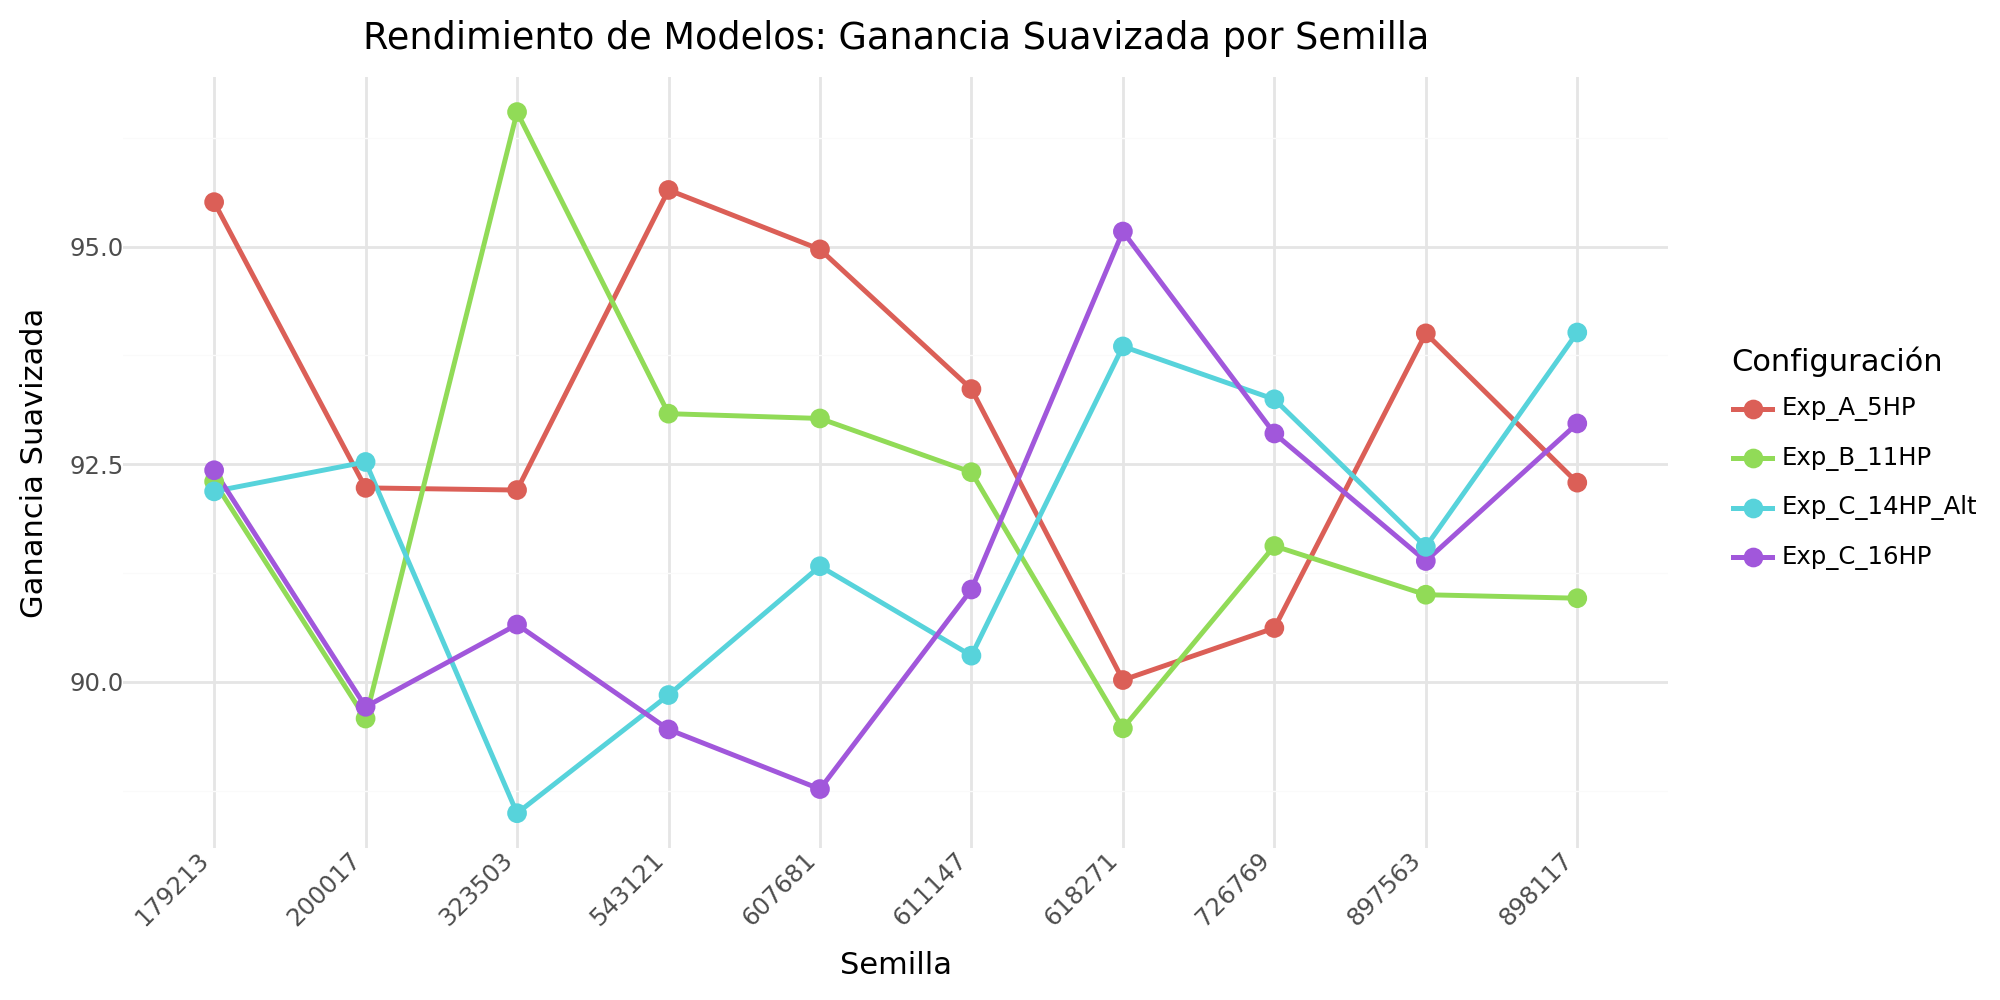


 📉 GRÁFICO 2: TRAYECTORIA DEL P-VALOR AL ACUMULAR EVIDENCIA


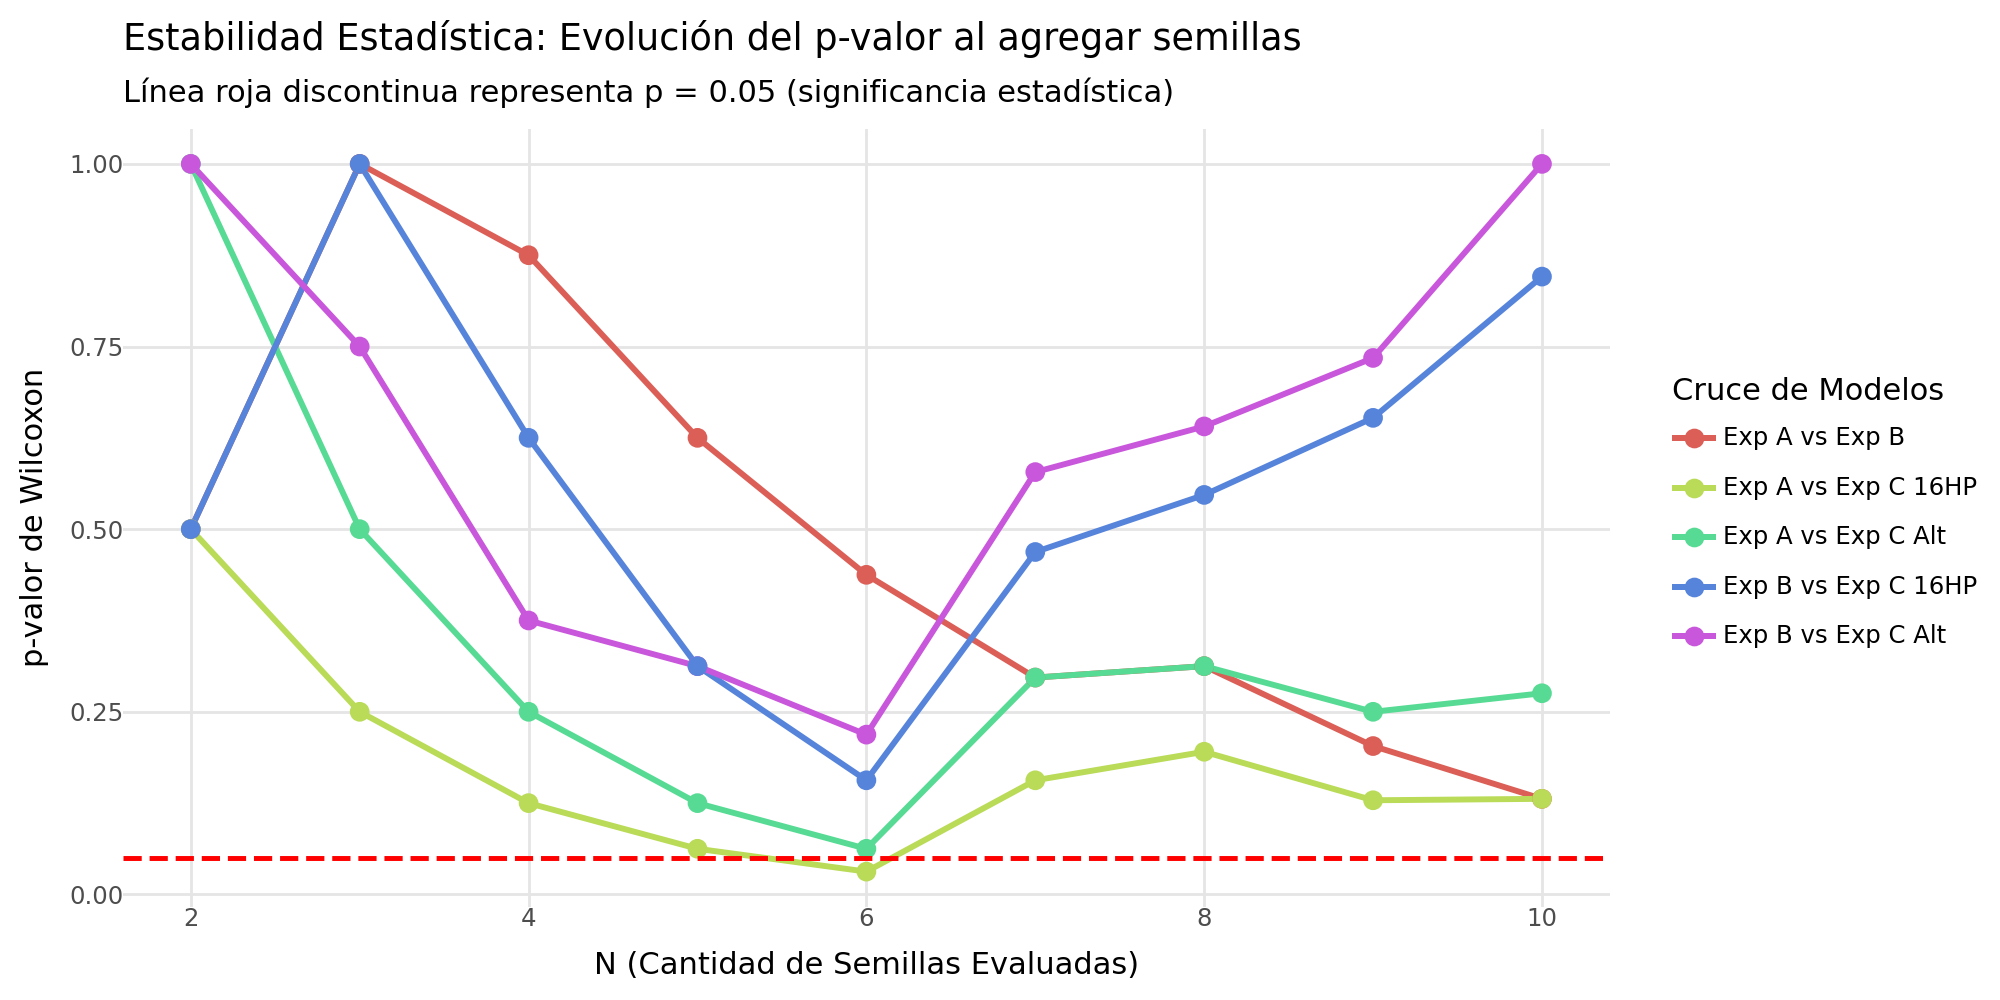


 💾 PREPARANDO EXPORTACIÓN Y RESUMEN PARA EL LLM...
✅ Archivo Excel consolidado guardado como: 'Resultados_Estadisticos_Definitivos.xlsx'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

⬇️ Descarga del Excel iniciada...

👇👇👇👇👇👇👇👇👇👇👇👇👇👇👇
 COPIÁ EL TEXTO DE ABAJO Y PEGALO EN EL CHAT 
👆👆👆👆👆👆👆👆👆👆👆👆👆👆👆

Acá están los resultados finales del Test de Wilcoxon para los 4 experimentos de mi tesis. Armame las conclusiones para la diapositiva:

■ ¿Aumentar de 5 a 11 HPs suma valor?
  - Comparación: Exp_A_5HP vs Exp_B_11HP
  - P-Valor: 0.1309 (N=10)
  - Diferencia Significativa (<0.05): No
  - Veredicto: Empate

■ ¿Pasar de 5 a 14 HPs (Seguro) suma valor?
  - Comparación: Exp_A_5HP vs Exp_C_14HP_Alt
  - P-Valor: 0.2754 (N=10)
  - Diferencia Significativa (<0.05): No
  - Veredicto: Empate

■ ¿Pasar de 5 a 16 HPs (Cuantización) suma valor?
  - Comparación: Exp_A_5HP vs Exp_C_16HP
  - P-Valor: 0.1309 (N=10)
  - Diferencia Significativa (<0.05): No
  - Veredicto: Empate

■ ¿Balance/nodo suma valor sobre Exp B?
  - Comparación: Exp_B_11HP vs Exp_C_14HP_Alt
  - P-Valor: 1.0 (N=10)
  - Diferencia Significativa (<0.05): No
  - Veredicto: Empate

■ ¿Vale el riesgo la cuantización frente a 

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import wilcoxon
import warnings
warnings.filterwarnings('ignore') # Ocultar advertencias de scipy por n pequeñas al iterar
from IPython.display import display
from google.colab import files

try:
    from plotnine import ggplot, aes, geom_line, geom_point, geom_hline, theme_minimal, labs, theme, element_text, element_blank
except ImportError:
    print("Instalando plotnine...")
    !pip install plotnine -q
    from plotnine import ggplot, aes, geom_line, geom_point, geom_hline, theme_minimal, labs, theme, element_text, element_blank

# =====================================================================
# 1. CARGA Y PROCESAMIENTO DE LOS EXCEL
# =====================================================================
archivos = {
    "Exp_A_5HP": "ExpA.xlsx",
    "Exp_B_11HP": "ExpB.xlsx",
    "Exp_C_16HP": "ExpC-16HP.xlsx",
    "Exp_C_14HP_Alt": "ExpC-Alternativo.xlsx"
}

resultados_por_exp = {}

for nombre_exp, ruta_archivo in archivos.items():
    try:
        df = pd.read_excel(ruta_archivo, sheet_name=0)
        col_semilla = [c for c in df.columns if 'semilla' in str(c).lower()][0]
        col_ganancia = [c for c in df.columns if 'ganancia' in str(c).lower()][0]

        df_limpio = df[[col_semilla, col_ganancia]].dropna().copy()
        df_limpio.columns = ['Semilla', nombre_exp]
        df_limpio['Semilla'] = df_limpio['Semilla'].astype(int)

        resultados_por_exp[nombre_exp] = df_limpio
    except FileNotFoundError:
        print(f"⚠️ Archivo no encontrado: {ruta_archivo}")

# Merge outer para unificar todo
df_ganancias = resultados_por_exp.get("Exp_A_5HP", pd.DataFrame())
for exp in ["Exp_B_11HP", "Exp_C_16HP", "Exp_C_14HP_Alt"]:
    if exp in resultados_por_exp:
        df_ganancias = df_ganancias.merge(resultados_por_exp[exp], on='Semilla', how='outer')

# Asegurar orden creciente de semillas para el test acumulativo
df_ganancias = df_ganancias.sort_values('Semilla').reset_index(drop=True)

# =====================================================================
# 2. TEST DE WILCOXON TRADICIONAL (MUESTRA COMPLETA)
# =====================================================================
def comparar_experimentos(df, col1, col2, pregunta):
    df_pair = df[['Semilla', col1, col2]].dropna()
    n_muestras = len(df_pair)
    if n_muestras < 2: return None

    stat, p_valor = wilcoxon(df_pair[col1], df_pair[col2])
    significativo = "Sí" if p_valor < 0.05 else "No"
    ganador = col1 if (significativo == "Sí" and df_pair[col1].median() > df_pair[col2].median()) else (col2 if significativo == "Sí" else "Empate")

    return {"Comparación": f"{col1} vs {col2}", "Hipótesis": pregunta, "N": n_muestras, "p-valor": round(p_valor, 4), "Dif (<0.05)": significativo, "Ganador": ganador}

# 5. Ejecutar comparaciones (Añadimos A vs C)
comparaciones = [
    comparar_experimentos(df_ganancias, 'Exp_A_5HP', 'Exp_B_11HP', "¿Aumentar de 5 a 11 HPs suma valor?"),

    # LAS NUEVAS COMPARACIONES DIRECTAS CONTRA EL BASELINE
    comparar_experimentos(df_ganancias, 'Exp_A_5HP', 'Exp_C_14HP_Alt', "¿Pasar de 5 a 14 HPs (Seguro) suma valor?"),
    comparar_experimentos(df_ganancias, 'Exp_A_5HP', 'Exp_C_16HP', "¿Pasar de 5 a 16 HPs (Cuantización) suma valor?"),

    # COMPARACIONES INCREMENTALES
    comparar_experimentos(df_ganancias, 'Exp_B_11HP', 'Exp_C_14HP_Alt', "¿Balance/nodo suma valor sobre Exp B?"),
    comparar_experimentos(df_ganancias, 'Exp_B_11HP', 'Exp_C_16HP', "¿Vale el riesgo la cuantización frente a B?"),
    comparar_experimentos(df_ganancias, 'Exp_C_14HP_Alt', 'Exp_C_16HP', "¿Cuantización vs Alt Seguro?")
]
df_test_final = pd.DataFrame([c for c in comparaciones if c is not None])
df_test_final = pd.DataFrame([c for c in comparaciones if c is not None])

print("="*60)
print(" 📊 TABLA A: GANANCIA MÁXIMA POR SEMILLA")
print("="*60)
display(df_ganancias.style.format(precision=2, na_rep="--"))

print("\n" + "="*60)
print(" 🔬 TABLA B: RESULTADOS WILCOXON (MUESTRA TOTAL)")
print("="*60)
display(df_test_final)

# =====================================================================
# 3. GRÁFICO 1: EVOLUCIÓN DE GANANCIAS POR EXPERIMENTO
# =====================================================================
df_long_ganancias = df_ganancias.melt(
    id_vars=['Semilla'],
    value_vars=[c for c in df_ganancias.columns if c != 'Semilla'],
    var_name='Experimento', value_name='Ganancia'
).dropna()

plot_ganancias = (
    ggplot(df_long_ganancias, aes(x='factor(Semilla)', y='Ganancia', color='Experimento', group='Experimento')) +
    geom_line(size=1) + geom_point(size=3) +
    theme_minimal() +
    labs(title="Rendimiento de Modelos: Ganancia Suavizada por Semilla", x="Semilla", y="Ganancia Suavizada", color="Configuración") +
    theme(axis_text_x=element_text(rotation=45, hjust=1), figure_size=(10, 5))
)

print("\n" + "="*60)
print(" 📈 GRÁFICO 1: GANANCIAS POR SEMILLA")
print("="*60)
display(plot_ganancias)

# =====================================================================
# 4. ANÁLISIS DE ROBUSTEZ: EVOLUCIÓN ACUMULADA DEL P-VALOR
# =====================================================================
pares_evolucion = [
    ('Exp_A_5HP', 'Exp_B_11HP', 'Exp A vs Exp B'),

    # AGREGAMOS LAS TRAYECTORIAS CONTRA EL BASELINE
    ('Exp_A_5HP', 'Exp_C_14HP_Alt', 'Exp A vs Exp C Alt'),
    ('Exp_A_5HP', 'Exp_C_16HP', 'Exp A vs Exp C 16HP'),

    ('Exp_B_11HP', 'Exp_C_14HP_Alt', 'Exp B vs Exp C Alt'),
    ('Exp_B_11HP', 'Exp_C_16HP', 'Exp B vs Exp C 16HP')
]

resultados_acumulados = []

for col1, col2, etiqueta in pares_evolucion:
    if col1 in df_ganancias.columns and col2 in df_ganancias.columns:
        sub_df = df_ganancias[['Semilla', col1, col2]].dropna().reset_index(drop=True)

        # Iterar desde N=2 hasta N=Total
        for i in range(2, len(sub_df) + 1):
            subset = sub_df.iloc[:i]
            try:
                stat, p_val = wilcoxon(subset[col1], subset[col2])
            except ValueError:
                p_val = 1.0 # Si las ganancias son idénticas y el N es chico, scipy puede lanzar error

            resultados_acumulados.append({
                'Comparacion': etiqueta,
                'Cantidad_Semillas': i,
                'P_Valor': p_val
            })

df_pvals = pd.DataFrame(resultados_acumulados)

plot_pvals = (
    ggplot(df_pvals, aes(x='Cantidad_Semillas', y='P_Valor', color='Comparacion', group='Comparacion')) +
    geom_line(size=1.2) + geom_point(size=3) +
    geom_hline(yintercept=0.05, linetype='dashed', color='red', size=1) + # Umbral de corte
    theme_minimal() +
    labs(
        title="Estabilidad Estadística: Evolución del p-valor al agregar semillas",
        subtitle="Línea roja discontinua representa p = 0.05 (significancia estadística)",
        x="N (Cantidad de Semillas Evaluadas)",
        y="p-valor de Wilcoxon",
        color="Cruce de Modelos"
    ) +
    theme(figure_size=(10, 5), panel_grid_minor=element_blank())
)

print("\n" + "="*60)
print(" 📉 GRÁFICO 2: TRAYECTORIA DEL P-VALOR AL ACUMULAR EVIDENCIA")
print("="*60)
display(plot_pvals)

# =====================================================================
# 5. EXPORTACIÓN DE RESULTADOS PARA EL LLM Y RESPALDO
# =====================================================================
print("\n" + "="*60)
print(" 💾 PREPARANDO EXPORTACIÓN Y RESUMEN PARA EL LLM...")
print("="*60)

# 1. Guardar todo en un Excel consolidado (múltiples hojas)
nombre_excel = 'Resultados_Estadisticos_Definitivos.xlsx'
with pd.ExcelWriter(nombre_excel, engine='openpyxl') as writer:
    df_ganancias.to_excel(writer, sheet_name='Ganancias_Semillas', index=False)
    df_test_final.to_excel(writer, sheet_name='Wilcoxon_Total', index=False)
    df_pvals.to_excel(writer, sheet_name='Wilcoxon_Acumulado', index=False)

print(f"✅ Archivo Excel consolidado guardado como: '{nombre_excel}'")

# Descargar automáticamente el archivo a tu computadora (Solo funciona en Colab)
try:
    from google.colab import files
    files.download(nombre_excel)
    print("⬇️ Descarga del Excel iniciada...")
except Exception as e:
    print("Nota: La descarga automática solo funciona en el entorno web de Colab.")

# 2. Imprimir bloque de texto optimizado para copiar y pegar al LLM
print("\n" + "👇" * 15)
print(" COPIÁ EL TEXTO DE ABAJO Y PEGALO EN EL CHAT ")
print("👆" * 15 + "\n")

texto_llm = "Acá están los resultados finales del Test de Wilcoxon para los 4 experimentos de mi tesis. Armame las conclusiones para la diapositiva:\n\n"
for index, row in df_test_final.iterrows():
    texto_llm += f"■ {row['Hipótesis']}\n"
    texto_llm += f"  - Comparación: {row['Comparación']}\n"
    texto_llm += f"  - P-Valor: {row['p-valor']} (N={row['N']})\n"
    texto_llm += f"  - Diferencia Significativa (<0.05): {row['Dif (<0.05)']}\n"
    texto_llm += f"  - Veredicto: {row['Ganador']}\n\n"

print(texto_llm)
print("-" * 60)